HED-XAI-P: HYBRID MULTI-SCALE ATTENTION MODEL
TensorFlow: 2.17.0
Dataset: D:\Downloads\Data Analysis\master\Phd\chest_xray_new
Expected folder layout: train/<class>, val/<class>, test/<class>
Output: D:\Downloads\HED_XAI_Pneumonia_Results
Requested epochs: 50

Class mapping:
  0: NORMAL
  1: PNEUMONIA

Image counts:
class_name  NORMAL  PNEUMONIA
split                        
test           238        642
train         1108       2991
val            240        640

Checking exact duplicate files across splits...
This does not detect visually similar images or patient-level overlap.
Found 4099 images belonging to 2 classes.
Found 880 images belonging to 2 classes.
Found 880 images belonging to 2 classes.

Train images: 4099; validation images: 880; test images: 880

Building hybrid pneumonia model...


Model: "HED_XAI_Pneumonia"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ pneumonia_image_in… │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ MobileNetV2_MultiS… │ [(None, 56, 56,   │  2,257,984 │ pneumonia_image_… │
│ (Functional)        │ 144), (None, 28,  │            │                   │
│                     │ 28, 192), (None,  │            │                   │
│                     │ 7, 7, 1280)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_pool_scale_1 │ (None, 144)       │          0 │ MobileNetV2_Mult… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_pool_scale_2 │ (None, 192)       │          0 │ MobileNetV2_Mult… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_pool_scale_3 │ (None, 1280)      │          0 │ MobileNetV2_Mult… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_scale_featur… │ (None, 1616)      │          0 │ global_pool_scal… │
│ (Concatenate)       │                   │            │ global_pool_scal… │
│                     │                   │            │ global_pool_scal… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fusion_batch_norm   │ (None, 1616)      │      6,464 │ multi_scale_feat… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fusion_projection   │ (None, 256)       │    413,952 │ fusion_batch_nor… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fusion_dropout      │ (None, 256)       │          0 │ fusion_projectio… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ channel_attention_… │ (None, 32)        │      8,224 │ fusion_dropout[0… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ channel_attention_… │ (None, 256)       │      8,448 │ channel_attentio… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ channel_attention_… │ (None, 256)       │          0 │ fusion_dropout[0… │
│ (Multiply)          │                   │            │ channel_attentio… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ classifier_dense    │ (None, 128)       │     32,896 │ channel_attentio… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ classifier_dropout  │ (None, 128)       │          0 │ classifier_dense… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pneumonia_class_pr… │ (None, 2)         │        258 │ classifier_dropo… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

Total params: 2,728,226 (10.41 MB)

Trainable params: 1,977,730 (7.54 MB)

Non-trainable params: 750,496 (2.86 MB)


Starting pneumonia model training for 50 epochs...
Epoch 1/50
257/257 ━━━━━━━━━━━━━━━━━━━━ 0s 347ms/step - accuracy: 0.8925 - loss: 0.2645
Epoch 1: val_loss improved from None to 0.58518, saving model to D:\Downloads\HED_XAI_Pneumonia_Results\HED_XAI_Pneumonia_Best.keras
257/257 ━━━━━━━━━━━━━━━━━━━━ 109s 403ms/step - accuracy: 0.9239 - loss: 0.1959 - val_accuracy: 0.7852 - val_loss: 0.5852 - learning_rate: 1.0000e-04
Epoch 2/50
257/257 ━━━━━━━━━━━━━━━━━━━━ 0s 340ms/step - accuracy: 0.9482 - loss: 0.1398
Epoch 2: val_loss did not improve from 0.58518
257/257 ━━━━━━━━━━━━━━━━━━━━ 98s 383ms/step - accuracy: 0.9500 - loss: 0.1391 - val_accuracy: 0.7523 - val_loss: 1.0727 - learning_rate: 1.0000e-04
Epoch 3/50
257/257 ━━━━━━━━━━━━━━━━━━━━ 0s 358ms/step - accuracy: 0.9479 - loss: 0.1345
Epoch 3: val_loss improved from 0.58518 to 0.09569, saving model to D:\Downloads\HED_XAI_Pneumonia_Results\HED_XAI_Pneumonia_Best.keras
257/257 ━━━━━━━━━━━━━━━━━━━━ 104s 404ms/step - accuracy: 0.9519 - loss:

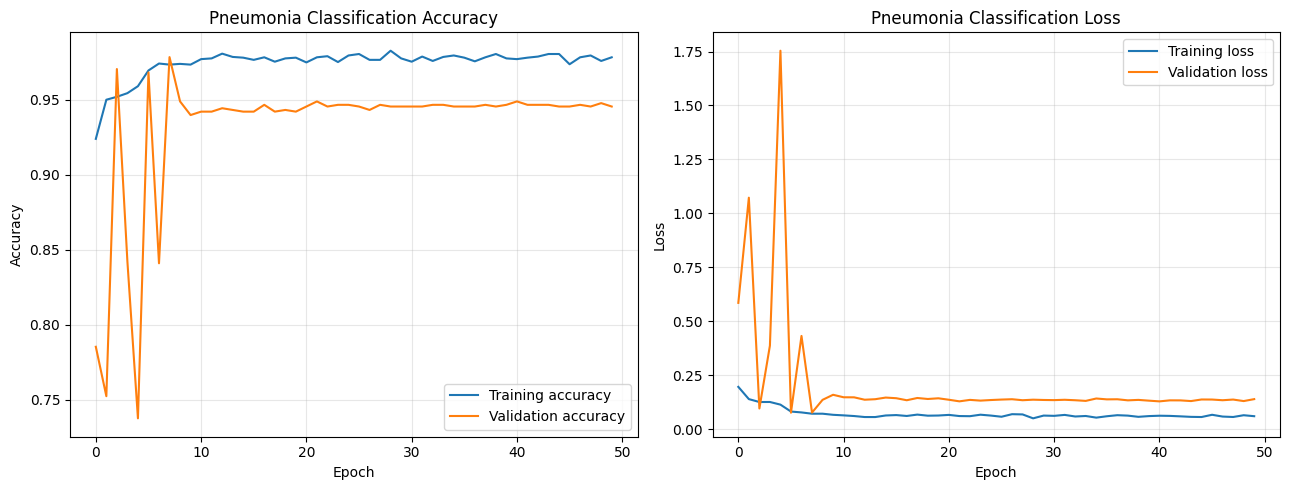

55/55 ━━━━━━━━━━━━━━━━━━━━ 15s 233ms/step - accuracy: 0.9841 - loss: 0.0438
55/55 ━━━━━━━━━━━━━━━━━━━━ 12s 203ms/step

FINAL TEST RESULTS -- HED-XAI-P
Test loss: 0.0438
Accuracy: 98.41%
Macro precision: 0.9850
Macro sensitivity/recall: 0.9746
Macro F1-score: 0.9796
Weighted precision: 0.9841
Weighted recall: 0.9841
Weighted F1-score: 0.9840
Macro ROC-AUC (one-vs-rest): 0.9991
Macro average precision: 0.9987

Confusion matrix (rows=actual, columns=predicted):
 [[227  11]
 [  3 639]]

Classification report:
              precision    recall  f1-score   support

      NORMAL     0.9870    0.9538    0.9701       238
   PNEUMONIA     0.9831    0.9953    0.9892       642

    accuracy                         0.9841       880
   macro avg     0.9850    0.9746    0.9796       880
weighted avg     0.9841    0.9841    0.9840       880



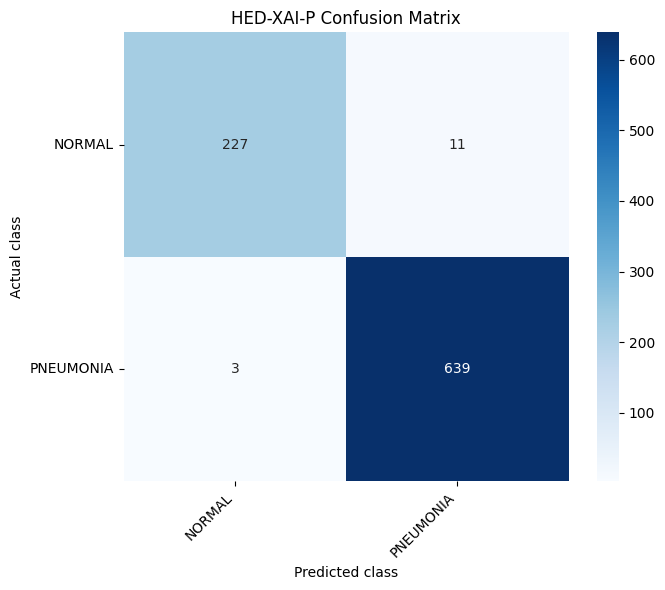

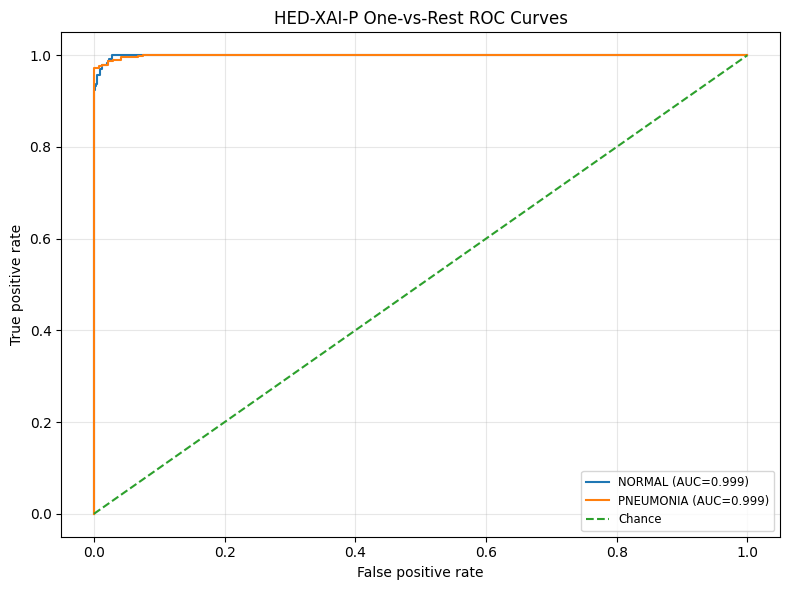

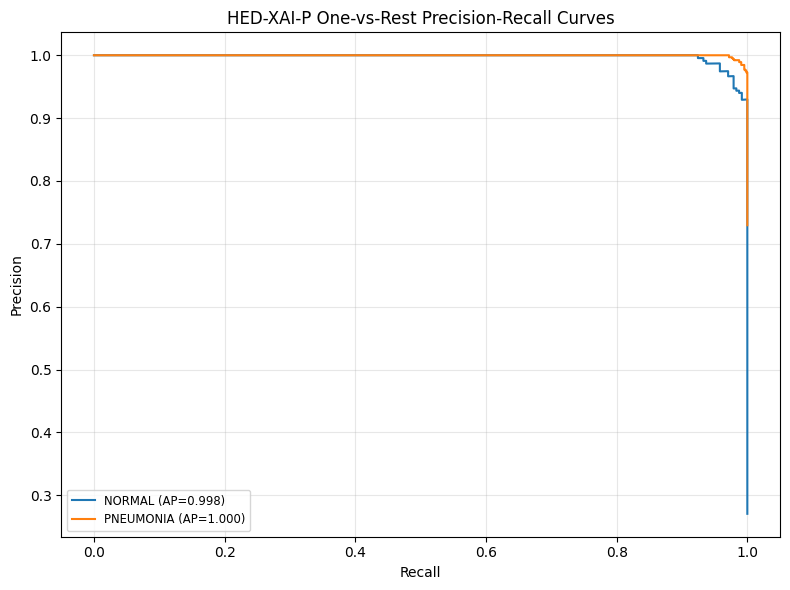


Final metrics table:
                               Metric                                                      Value
                               Model                                                  HED-XAI-P
                        Architecture MobileNetV2 multi-scale feature fusion + channel attention
                             Classes                                          NORMAL, PNEUMONIA
                   Number of classes                                                          2
                          Input size                                              224 x 224 x 3
                    Requested epochs                                                         50
                    Epochs completed                                                         50
          Best validation-loss epoch                                                          6
                          Batch size                                                         16
                 

In [1]:
# HED-XAI-P: Hybrid MobileNetV2 Multi-Scale Attention for Pneumonia Classification
# Trains for 50 epochs on existing chest X-ray train/val/test directory splits.
# Research prototype only; not a clinically validated diagnostic tool.

import os, json, time, random, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score,
    roc_curve, precision_recall_curve, average_precision_score, auc
)
from sklearn.preprocessing import label_binarize
from tensorflow.keras import Model
from tensorflow.keras.layers import (
    Input, Dense, Dropout, GlobalAveragePooling2D, Concatenate,
    Multiply, BatchNormalization
)
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau, CSVLogger
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.models import load_model

# ============================================================
# 1. CONFIGURATION
# ============================================================
SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 16          # Reduce to 8 if memory is limited.
EPOCHS = 50
LEARNING_RATE = 1e-4
FINE_TUNE_LAST_LAYERS = 30

base_dir = r"D:\Downloads\Data Analysis\master\Phd\chest_xray_new"
train_dir = r"D:\Downloads\Data Analysis\master\Phd\chest_xray_new\train"
val_dir   = r"D:\Downloads\Data Analysis\master\Phd\chest_xray_new\val"
test_dir  = r"D:\Downloads\Data Analysis\master\Phd\chest_xray_new\test"
OUTPUT_DIR = r"D:\Downloads\HED_XAI_Pneumonia_Results"
VALID_EXTENSIONS = (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")
os.makedirs(OUTPUT_DIR, exist_ok=True)

BEST_MODEL_PATH = os.path.join(OUTPUT_DIR, "HED_XAI_Pneumonia_Best.keras")
FINAL_MODEL_PATH = os.path.join(OUTPUT_DIR, "HED_XAI_Pneumonia_Final.keras")
RESULTS_CSV = os.path.join(OUTPUT_DIR, "HED_XAI_Pneumonia_Final_Metrics.csv")
REPORT_CSV = os.path.join(OUTPUT_DIR, "HED_XAI_Pneumonia_Classification_Report.csv")
PREDICTIONS_CSV = os.path.join(OUTPUT_DIR, "HED_XAI_Pneumonia_Test_Predictions.csv")
TRAINING_LOG = os.path.join(OUTPUT_DIR, "HED_XAI_Pneumonia_Training_Log.csv")
CONFIG_FILE = os.path.join(OUTPUT_DIR, "HED_XAI_Pneumonia_Experiment_Config.json")
HISTORY_CSV = os.path.join(OUTPUT_DIR, "HED_XAI_Pneumonia_History.csv")

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("=" * 72)
print("HED-XAI-P: HYBRID MULTI-SCALE ATTENTION MODEL")
print("=" * 72)
print("TensorFlow:", tf.__version__)
print("Dataset:", base_dir)
print("Expected folder layout: train/<class>, val/<class>, test/<class>")
print("Output:", OUTPUT_DIR)
print("Requested epochs:", EPOCHS)

# ============================================================
# 2. VALIDATE SPLIT FOLDERS AND DETECT CLASSES AUTOMATICALLY
# ============================================================
for folder in (train_dir, val_dir, test_dir):
    if not os.path.isdir(folder):
        raise FileNotFoundError(f"Dataset folder not found: {folder}")

CLASS_NAMES = sorted(p.name for p in Path(train_dir).iterdir() if p.is_dir())
if len(CLASS_NAMES) < 2:
    raise ValueError(f"Expected at least two class folders in {train_dir}; found {CLASS_NAMES}")

for split_name, folder in (("val", val_dir), ("test", test_dir)):
    found = sorted(p.name for p in Path(folder).iterdir() if p.is_dir())
    if found != CLASS_NAMES:
        raise ValueError(
            f"Class folders in {split_name} must match train.\n"
            f"Train: {CLASS_NAMES}\n{split_name}: {found}"
        )

NUM_CLASSES = len(CLASS_NAMES)
CLASS_TO_INDEX = {name: i for i, name in enumerate(CLASS_NAMES)}
print("\nClass mapping:")
for name, index in CLASS_TO_INDEX.items():
    print(f"  {index}: {name}")

# Count images and create a manifest; flag exact duplicate files across splits.
def collect_records(split_name, folder):
    records = []
    for class_name in CLASS_NAMES:
        class_dir = Path(folder) / class_name
        files = sorted(p for p in class_dir.rglob("*")
                       if p.is_file() and p.suffix.lower() in VALID_EXTENSIONS)
        if not files:
            raise ValueError(f"No images found in {class_dir}")
        for file_path in files:
            records.append({
                "split": split_name, "image_path": str(file_path),
                "class_name": class_name, "label": CLASS_TO_INDEX[class_name]
            })
    return records

manifest = pd.DataFrame(
    collect_records("train", train_dir)
    + collect_records("val", val_dir)
    + collect_records("test", test_dir)
)
print("\nImage counts:")
print(pd.crosstab(manifest["split"], manifest["class_name"]).to_string())
manifest.to_csv(os.path.join(OUTPUT_DIR, "HED_XAI_Pneumonia_Split_Manifest.csv"), index=False)

def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

print("\nChecking exact duplicate files across splits...")
manifest["sha256"] = manifest["image_path"].apply(sha256_file)
hash_split_counts = manifest.groupby("sha256")["split"].nunique()
overlap = hash_split_counts[hash_split_counts > 1]
if len(overlap):
    print(f"WARNING: {len(overlap)} byte-identical image(s) occur in multiple splits.")
else:
    print("No byte-identical images overlap across splits.")
print("This does not detect visually similar images or patient-level overlap.")

# ============================================================
# 3. IMAGE GENERATORS
# ============================================================
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=5, width_shift_range=0.03, height_shift_range=0.03,
    zoom_range=0.05, horizontal_flip=False, fill_mode="nearest"
)
eval_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

train_generator = train_datagen.flow_from_directory(
    train_dir, target_size=(IMG_SIZE, IMG_SIZE), color_mode="rgb",
    classes=CLASS_NAMES, class_mode="sparse", batch_size=BATCH_SIZE,
    shuffle=True, seed=SEED
)
val_generator = eval_datagen.flow_from_directory(
    val_dir, target_size=(IMG_SIZE, IMG_SIZE), color_mode="rgb",
    classes=CLASS_NAMES, class_mode="sparse", batch_size=BATCH_SIZE, shuffle=False
)
test_generator = eval_datagen.flow_from_directory(
    test_dir, target_size=(IMG_SIZE, IMG_SIZE), color_mode="rgb",
    classes=CLASS_NAMES, class_mode="sparse", batch_size=BATCH_SIZE, shuffle=False
)
assert train_generator.class_indices == val_generator.class_indices == test_generator.class_indices
train_count, val_count, test_count = (
    train_generator.samples, val_generator.samples, test_generator.samples
)
print(f"\nTrain images: {train_count}; validation images: {val_count}; test images: {test_count}")

# ============================================================
# 4. HYBRID MULTI-SCALE MODEL + CHANNEL ATTENTION
# ============================================================
print("\nBuilding hybrid pneumonia model...")
backbone = MobileNetV2(
    weights="imagenet", include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3)
)
feature_layer_names = ["block_3_expand_relu", "block_6_expand_relu", "out_relu"]
feature_extractor = Model(
    inputs=backbone.input,
    outputs=[backbone.get_layer(name).output for name in feature_layer_names],
    name="MobileNetV2_MultiScale_Extractor"
)
backbone.trainable = True
for layer in backbone.layers:
    layer.trainable = False
for layer in backbone.layers[-FINE_TUNE_LAST_LAYERS:]:
    if not isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = True

inputs = Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="pneumonia_image_input")
feature_maps = feature_extractor(inputs, training=False)
pooled = [
    GlobalAveragePooling2D(name=f"global_pool_scale_{i+1}")(feature_map)
    for i, feature_map in enumerate(feature_maps)
]
fused = Concatenate(name="multi_scale_feature_fusion")(pooled)
fused = BatchNormalization(name="fusion_batch_norm")(fused)
fused = Dense(256, activation="relu", name="fusion_projection")(fused)
fused = Dropout(0.35, name="fusion_dropout")(fused)
attention = Dense(32, activation="relu", name="channel_attention_hidden")(fused)
attention = Dense(256, activation="sigmoid", name="channel_attention_weights")(attention)
attended = Multiply(name="channel_attention_refinement")([fused, attention])
x = Dense(128, activation="relu", name="classifier_dense")(attended)
x = Dropout(0.25, name="classifier_dropout")(x)
outputs = Dense(NUM_CLASSES, activation="softmax", name="pneumonia_class_probabilities")(x)

model = Model(inputs, outputs, name="HED_XAI_Pneumonia")
model.compile(
    optimizer=Adam(learning_rate=LEARNING_RATE),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()

config = {
    "model_name": "HED-XAI-P",
    "architecture": "MobileNetV2 multiscale feature fusion + channel attention + softmax",
    "base_dir": base_dir, "classes": CLASS_TO_INDEX,
    "input_size": [IMG_SIZE, IMG_SIZE, 3], "epochs": EPOCHS,
    "batch_size": BATCH_SIZE, "optimizer": "Adam",
    "learning_rate": LEARNING_RATE, "fine_tune_last_layers": FINE_TUNE_LAST_LAYERS,
    "seed": SEED, "preprocessing": "MobileNetV2 preprocess_input"
}
with open(CONFIG_FILE, "w", encoding="utf-8") as f:
    json.dump(config, f, indent=4)

callbacks = [
    ModelCheckpoint(BEST_MODEL_PATH, monitor="val_loss", save_best_only=True,
                    mode="min", verbose=1),
    ReduceLROnPlateau(monitor="val_loss", factor=0.2, patience=2,
                      min_lr=1e-7, mode="min", verbose=1),
    CSVLogger(TRAINING_LOG, append=False)
]

# ============================================================
# 5. TRAIN FOR 50 EPOCHS (NO EARLY STOPPING)
# ============================================================
print("\nStarting pneumonia model training for 50 epochs...")
training_start = time.perf_counter()
history = model.fit(
    train_generator, validation_data=val_generator, epochs=EPOCHS,
    callbacks=callbacks, verbose=1
)
training_seconds = time.perf_counter() - training_start
actual_epochs = len(history.history["loss"])
best_epoch = int(np.argmin(history.history["val_loss"])) + 1
print(f"\nEpochs completed: {actual_epochs}")
print(f"Best validation-loss epoch: {best_epoch}")
print(f"Training time: {training_seconds:.2f} seconds ({training_seconds/60:.2f} minutes)")
model.save(FINAL_MODEL_PATH)

history_df = pd.DataFrame(history.history)
history_df.insert(0, "epoch", np.arange(1, len(history_df) + 1))
history_df.to_csv(HISTORY_CSV, index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(history.history["accuracy"], label="Training accuracy")
axes[0].plot(history.history["val_accuracy"], label="Validation accuracy")
axes[0].set_title("Pneumonia Classification Accuracy")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Accuracy"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(history.history["loss"], label="Training loss")
axes[1].plot(history.history["val_loss"], label="Validation loss")
axes[1].set_title("Pneumonia Classification Loss")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Loss"); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "HED_XAI_Pneumonia_Training_Curves.png"), dpi=300)
plt.show()

# ============================================================
# 6. HELD-OUT TEST EVALUATION
# ============================================================
best_model = load_model(BEST_MODEL_PATH)
test_generator.reset()
test_loss, test_accuracy = best_model.evaluate(test_generator, verbose=1)

# Warm up then time inference on the full test set.
test_generator.reset()
warmup_images, _ = next(test_generator)
_ = best_model.predict(warmup_images[:min(4, len(warmup_images))], verbose=0)
test_generator.reset()
inference_start = time.perf_counter()
y_prob = best_model.predict(test_generator, verbose=1)
inference_seconds = time.perf_counter() - inference_start

y_true = test_generator.classes.astype(int)
if len(y_true) != len(y_prob):
    raise ValueError(f"Prediction count {len(y_prob)} != test-label count {len(y_true)}")
y_pred = np.argmax(y_prob, axis=1)
accuracy = accuracy_score(y_true, y_pred)
precision_macro = precision_score(y_true, y_pred, average="macro", zero_division=0)
recall_macro = recall_score(y_true, y_pred, average="macro", zero_division=0)
f1_macro = f1_score(y_true, y_pred, average="macro", zero_division=0)
precision_weighted = precision_score(y_true, y_pred, average="weighted", zero_division=0)
recall_weighted = recall_score(y_true, y_pred, average="weighted", zero_division=0)
f1_weighted = f1_score(y_true, y_pred, average="weighted", zero_division=0)
cm = confusion_matrix(y_true, y_pred, labels=np.arange(NUM_CLASSES))

y_true_bin = label_binarize(y_true, classes=np.arange(NUM_CLASSES))
if NUM_CLASSES == 2:
    y_true_bin = np.column_stack([1 - y_true, y_true])
try:
    roc_auc_macro = roc_auc_score(y_true_bin, y_prob, average="macro")
except ValueError:
    roc_auc_macro = float("nan")
try:
    pr_auc_macro = average_precision_score(y_true_bin, y_prob, average="macro")
except ValueError:
    pr_auc_macro = float("nan")

inference_ms_per_image = inference_seconds / len(y_true) * 1000 if len(y_true) else 0.0
throughput = len(y_true) / inference_seconds if inference_seconds > 0 else 0.0

print("\n" + "=" * 72)
print("FINAL TEST RESULTS -- HED-XAI-P")
print("=" * 72)
print(f"Test loss: {test_loss:.4f}")
print(f"Accuracy: {accuracy*100:.2f}%")
print(f"Macro precision: {precision_macro:.4f}")
print(f"Macro sensitivity/recall: {recall_macro:.4f}")
print(f"Macro F1-score: {f1_macro:.4f}")
print(f"Weighted precision: {precision_weighted:.4f}")
print(f"Weighted recall: {recall_weighted:.4f}")
print(f"Weighted F1-score: {f1_weighted:.4f}")
print(f"Macro ROC-AUC (one-vs-rest): {roc_auc_macro:.4f}")
print(f"Macro average precision: {pr_auc_macro:.4f}")
print("\nConfusion matrix (rows=actual, columns=predicted):\n", cm)
print("\nClassification report:")
print(classification_report(
    y_true, y_pred, labels=np.arange(NUM_CLASSES),
    target_names=CLASS_NAMES, digits=4, zero_division=0
))
report_dict = classification_report(
    y_true, y_pred, labels=np.arange(NUM_CLASSES),
    target_names=CLASS_NAMES, digits=4, zero_division=0, output_dict=True
)
pd.DataFrame(report_dict).transpose().to_csv(REPORT_CSV)

predictions = pd.DataFrame({
    "image_path": test_generator.filepaths,
    "actual_label": y_true,
    "actual_class": [CLASS_NAMES[i] for i in y_true],
    "predicted_label": y_pred,
    "predicted_class": [CLASS_NAMES[i] for i in y_pred],
    "correct_prediction": y_true == y_pred
})
for i, class_name in enumerate(CLASS_NAMES):
    safe_name = "".join(c if c.isalnum() else "_" for c in class_name).strip("_")
    predictions[f"probability_{safe_name}"] = y_prob[:, i]
predictions.to_csv(PREDICTIONS_CSV, index=False)

# Confusion matrix plot.
plt.figure(figsize=(max(7, NUM_CLASSES*1.3), max(6, NUM_CLASSES*1.1)))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel("Predicted class"); plt.ylabel("Actual class")
plt.title("HED-XAI-P Confusion Matrix")
plt.xticks(rotation=45, ha="right"); plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "HED_XAI_Pneumonia_Confusion_Matrix.png"), dpi=300)
plt.show()

# One-vs-rest ROC curves.
plt.figure(figsize=(8, 6))
for i, class_name in enumerate(CLASS_NAMES):
    if len(np.unique(y_true_bin[:, i])) < 2:
        continue
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_prob[:, i])
    plt.plot(fpr, tpr, label=f"{class_name} (AUC={auc(fpr, tpr):.3f})")
plt.plot([0, 1], [0, 1], "--", label="Chance")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("HED-XAI-P One-vs-Rest ROC Curves")
plt.legend(loc="lower right", fontsize="small"); plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "HED_XAI_Pneumonia_ROC_Curves.png"), dpi=300)
plt.show()

# One-vs-rest precision-recall curves.
plt.figure(figsize=(8, 6))
for i, class_name in enumerate(CLASS_NAMES):
    if len(np.unique(y_true_bin[:, i])) < 2:
        continue
    pr_precision, pr_recall, _ = precision_recall_curve(y_true_bin[:, i], y_prob[:, i])
    ap = average_precision_score(y_true_bin[:, i], y_prob[:, i])
    plt.plot(pr_recall, pr_precision, label=f"{class_name} (AP={ap:.3f})")
plt.xlabel("Recall"); plt.ylabel("Precision")
plt.title("HED-XAI-P One-vs-Rest Precision-Recall Curves")
plt.legend(loc="lower left", fontsize="small"); plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "HED_XAI_Pneumonia_PR_Curves.png"), dpi=300)
plt.show()

# ============================================================
# 7. MODEL SIZE AND FINAL METRICS TABLE
# ============================================================
total_params = best_model.count_params()
trainable_params = int(sum(np.prod(v.shape) for v in best_model.trainable_weights))
non_trainable_params = int(sum(np.prod(v.shape) for v in best_model.non_trainable_weights))
model_size_mb = os.path.getsize(BEST_MODEL_PATH) / (1024**2)

results = [
    ("Model", "HED-XAI-P"),
    ("Architecture", "MobileNetV2 multi-scale feature fusion + channel attention"),
    ("Classes", ", ".join(CLASS_NAMES)),
    ("Number of classes", NUM_CLASSES),
    ("Input size", f"{IMG_SIZE} x {IMG_SIZE} x 3"),
    ("Requested epochs", EPOCHS),
    ("Epochs completed", actual_epochs),
    ("Best validation-loss epoch", best_epoch),
    ("Batch size", BATCH_SIZE),
    ("Training images", train_count),
    ("Validation images", val_count),
    ("Test images", test_count),
    ("Test loss", float(test_loss)),
    ("Test accuracy (%)", accuracy*100),
    ("Macro precision", precision_macro),
    ("Macro sensitivity/recall", recall_macro),
    ("Macro F1-score", f1_macro),
    ("Weighted precision", precision_weighted),
    ("Weighted recall", recall_weighted),
    ("Weighted F1-score", f1_weighted),
    ("Macro ROC-AUC (OvR)", roc_auc_macro),
    ("Macro average precision", pr_auc_macro),
    ("Total parameters", total_params),
    ("Trainable parameters", trainable_params),
    ("Non-trainable parameters", non_trainable_params),
    ("Best model size (MB)", model_size_mb),
    ("Training time (seconds)", training_seconds),
    ("Training time (minutes)", training_seconds/60),
    ("Test inference time (seconds)", inference_seconds),
    ("Inference time per image (ms)", inference_ms_per_image),
    ("Inference throughput (images/second)", throughput),
    ("Random seed", SEED)
]
results_df = pd.DataFrame(results, columns=["Metric", "Value"])
results_df.to_csv(RESULTS_CSV, index=False)
print("\nFinal metrics table:\n", results_df.to_string(index=False))
print("\nSaved results in:", OUTPUT_DIR)
print("Best model:", BEST_MODEL_PATH)
print("Final model:", FINAL_MODEL_PATH)
print("Use the best checkpoint for Grad-CAM analysis.")
print("Research note: verify patient-level independence and test on external data where possible.")
